In [1]:
#Import core libraries
import numpy as np

import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt

In [2]:
IMAGE_SIZE = 256   # every image is resized to 256 x 256 pixels
BATCH_SIZE = 32    # number of images processed per training step
CHANNELS = 3       # RGB images have 3 colour channels
EPOCHS = 50        # number of full passes over the training data

In [3]:
# Load all images from the "PlantVillage" folder.
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "PlantVillage",
    batch_size= BATCH_SIZE,
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    shuffle=True,   # shuffle images so batches are not ordered by class
)

Found 2152 files belonging to 3 classes.


In [4]:
# Class names come from the folder names
class_names = dataset.class_names
class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

In [5]:
len(dataset)

68

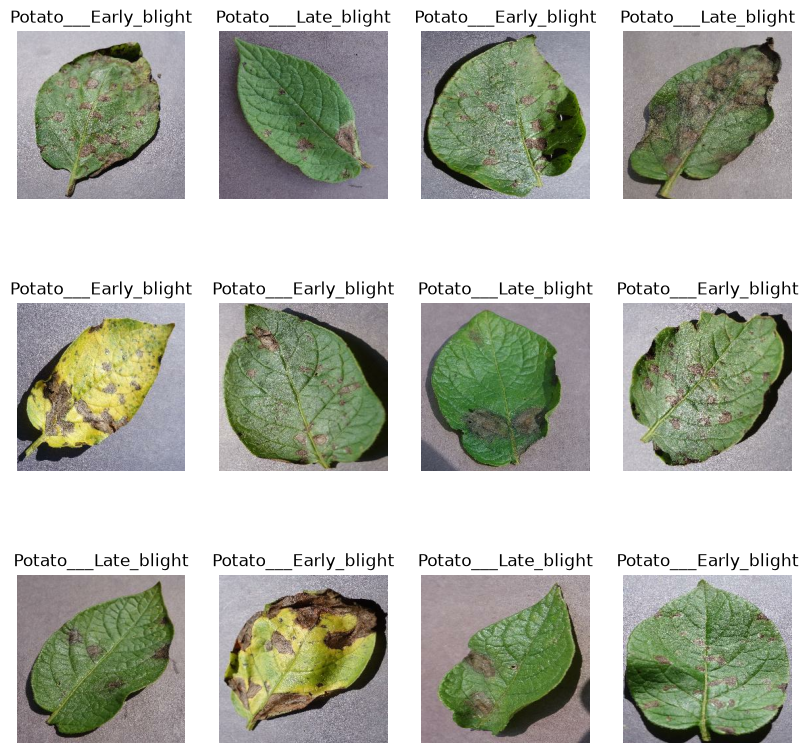

In [6]:
# Visual check: show the first 12 images of one batch with their class labels
plt.figure(figsize = (10, 10))
for image_batch, label_batch in dataset.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i+1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))   # convert tensor to displayable image
        plt.title(class_names[label_batch[i]])
        plt.axis("off")

In [7]:
# Reusable function that does the 80/10/10 split automatically
def get_dataset_partitions_tf(data, train_split=0.8, val_split=0.1, test_split=0.1, shuffle=True, shuffle_size=100):
    
    data_size = len(data)   # total number of batches

    if shuffle:
        
        data = data.shuffle(shuffle_size, seed=12)

    train_size = int(train_split * data_size)
    val_size = int(val_split * data_size)

    train_data = data.take(train_size)                              # first 80%
    val_data = data.skip(train_size).take(val_size)                 # next 10%
    test_data = data.skip(train_size).skip(val_size)                # remaining 10%

    return train_data, val_data, test_data

In [8]:
# Apply the split function to the full dataset
train_data, val_data, test_data = get_dataset_partitions_tf(dataset)

In [9]:
# Number of training batches
len(train_data), len(val_data), len(test_data)

(54, 6, 8)

In [10]:
# Input pipeline optimisation:
#   cache()    - keeps images in memory after the first epoch so they are not re-read from disk
#   shuffle()  - reshuffles batches so training order varies
#   prefetch() - prepares the next batch while the current one is training (faster training)
train_data = train_data.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_data = val_data.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
test_data = test_data.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

In [11]:
# Preprocessing layers (part of the model):
# resize to the expected size and scale pixel values from 0-255 to 0-1
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    layers.Rescaling(1.0/255),
])

In [12]:
# Data augmentation: random flips and rotations create varied copies of the images, which helps the model generalise and reduces overfitting.
# These layers are only active during training, not during evaluation/prediction.
data_augumentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),   # rotate by up to 20% of a full turn
])

In [13]:
# Input shape includes the batch size: (batch, height, width, channels)
input_shape = (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
# Number of output classes (must match the number of folders in the dataset)
n_classes = 3

In [14]:
# CNN architecture
model = models.Sequential([
    resize_and_rescale,      # preprocessing
    data_augumentation,      # augmentation (training only)
    
    # Convolution + pooling blocks: Conv2D learns visual features (edges, textures, spots),
    # MaxPooling halves the image size to keep the strongest features and reduce computation.
    layers.Conv2D(32, (3, 3), activation = "relu", input_shape = input_shape),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, kernel_size = (3, 3), activation = "relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, kernel_size = (3, 3), activation = "relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation = "relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation = "relu"),
    layers.MaxPooling2D((2, 2)),
        
    layers.Conv2D(64, kernel_size = (3, 3), activation = "relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),                                # turn feature maps into a 1D vector
    layers.Dense(64, activation = "relu"),           # fully connected layer for classification
    layers.Dense(n_classes, activation = "softmax")  # output: probability for each class
])

# Build the model with a known input shape so weights are created and summary() works
model.build(input_shape = input_shape)

C:\Users\DHAMI01\anaconda3\envs\mlenv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
# Show layers, output shapes and number of parameters
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (32, 256, 256, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ sequential_1 (Sequential)            │ (32, 256, 256, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (32, 254, 254, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (32, 127, 127, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (32, 125, 125, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (32, 62, 62, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (32, 60, 60, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (32, 30, 30, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (32, 28, 28, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (32, 14, 14, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (32, 12, 12, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (32, 6, 6, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (32, 4, 4, 64)              │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (32, 2, 2, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (32, 256)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (32, 64)                    │          16,448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (32, 3)                     │             195 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 183,747 (717.76 KB)

 Trainable params: 183,747 (717.76 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Training configuration
model.compile(
    optimizer = "adam",   
    loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits = False),
    metrics = ["accuracy"]
)

In [17]:
# Train the model; validation_data is used to monitor performance on unseen data each epoch

history = model.fit(
    train_data,
    epochs = EPOCHS,
    batch_size = BATCH_SIZE,
    verbose = 1,
    validation_data = val_data
)

Epoch 1/50


C:\Users\DHAMI01\anaconda3\envs\mlenv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


54/54 ━━━━━━━━━━━━━━━━━━━━ 13606s 255s/step - accuracy: 0.4693 - loss: 0.9269 - val_accuracy: 0.4948 - val_loss: 0.8432
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 367s 7s/step - accuracy: 0.6464 - loss: 0.7725 - val_accuracy: 0.7865 - val_loss: 0.5645
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 263s 5s/step - accuracy: 0.7766 - loss: 0.5586 - val_accuracy: 0.7656 - val_loss: 0.5207
Epoch 4/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 267s 5s/step - accuracy: 0.8247 - loss: 0.4442 - val_accuracy: 0.8750 - val_loss: 0.2893
Epoch 5/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 257s 5s/step - accuracy: 0.8617 - loss: 0.3260 - val_accuracy: 0.9010 - val_loss: 0.2569
Epoch 6/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 255s 5s/step - accuracy: 0.8819 - loss: 0.2992 - val_accuracy: 0.8958 - val_loss: 0.2800
Epoch 7/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 255s 5s/step - accuracy: 0.8814 - loss: 0.3051 - val_accuracy: 0.9010 - val_loss: 0.2086
Epoch 8/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 254s 5s/step - accuracy: 0.8981 - loss: 0.2604 - val_accuracy: 0.8906 - val_loss

In [18]:
# Final evaluation on the test set (data the model never saw during training)
scores = model.evaluate(test_data)

8/8 ━━━━━━━━━━━━━━━━━━━━ 118s 2s/step - accuracy: 0.9570 - loss: 0.1019


In [19]:
history.params

{'verbose': 1, 'epochs': 50, 'steps': 54}

In [20]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [21]:
# Extract the per-epoch metrics for plotting
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]

Text(0.5, 1.0, 'Training and Validation Loss')

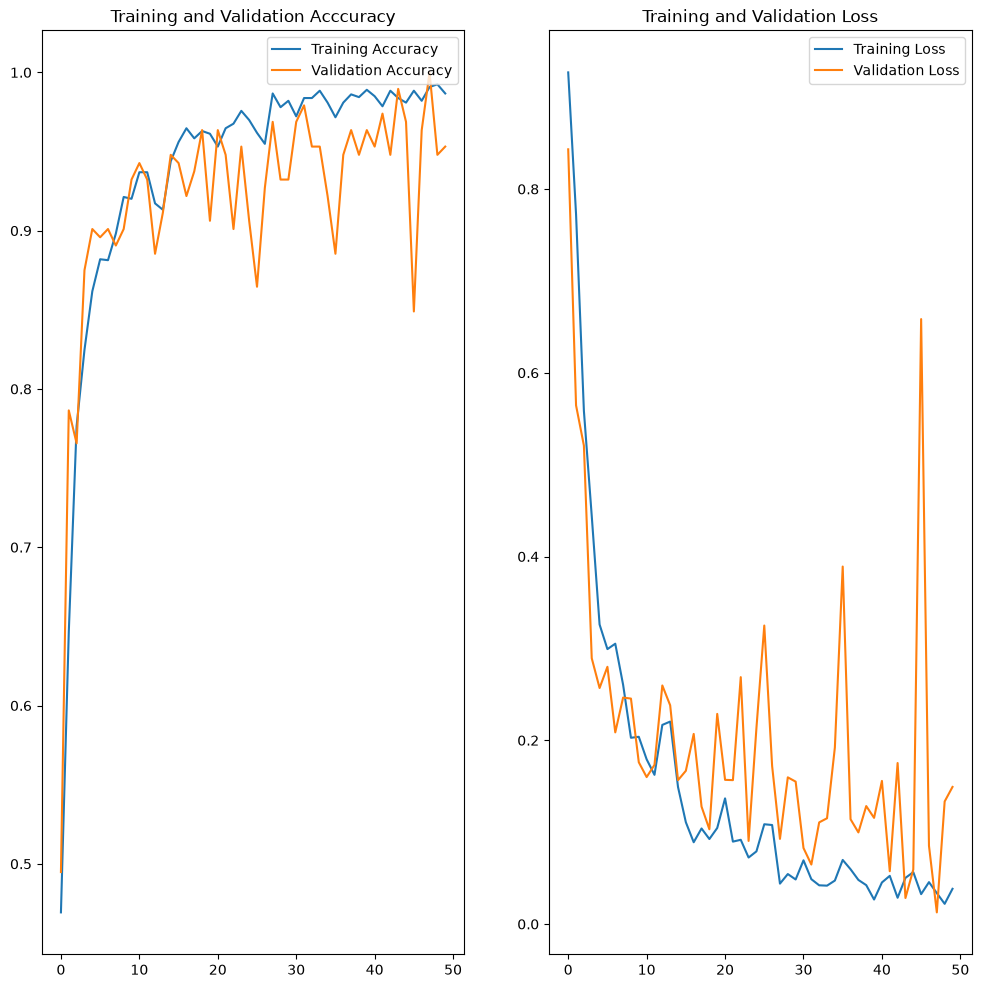

In [22]:
# Learning curves: compare training vs validation to spot overfitting
plt.figure(figsize = (12, 12))

# Left: accuracy
plt.subplot(1, 2, 1)
plt.plot(range(EPOCHS), acc, label = "Training Accuracy")
plt.plot(range(EPOCHS), val_acc, label = "Validation Accuracy")
plt.legend(loc= "upper right")
plt.title("Training and Validation Acccuracy")

# Right: loss
plt.subplot(1, 2, 2)
plt.plot(range(EPOCHS), loss, label = "Training Loss")
plt.plot(range(EPOCHS), val_loss, label = "Validation Loss")
plt.legend(loc= "upper right")
plt.title("Training and Validation Loss")

First image to predict
actual label:  Potato___Early_blight
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
predicted label:  Potato___Early_blight


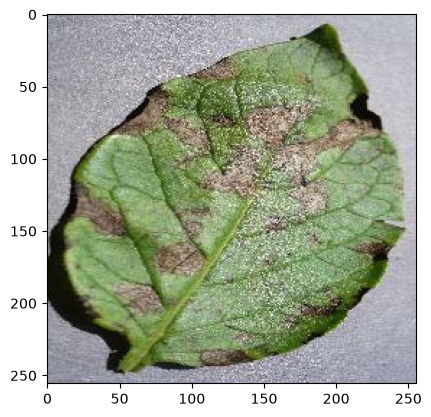

In [23]:
# Test the model on one image from a test batch
for images_batch, labels_batch in test_data.take(1):

    first_image = images_batch[0].numpy().astype("uint8")
    first_label = labels_batch[0].numpy()

    print("First image to predict")
    plt.imshow(first_image)
    print('actual label: ', class_names[first_label])

    batch_prediction = model.predict(images_batch)
    # argmax picks the class with the highest probability
    print("predicted label: ", class_names[np.argmax(batch_prediction[0])])

In [26]:
# function that predicts the class and confidence (%) for a single image
def predict(model, img):
    
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0) #Create a batch (model expects a batch dimension)

    predictions = model.predict(img_array)

    predicted_class = class_names[np.argmax(predictions[0])]     # most likely class
    confidence = round(100 * (np.max(predictions[0])), 2)        # its probability in %
    return predicted_class, confidence

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step


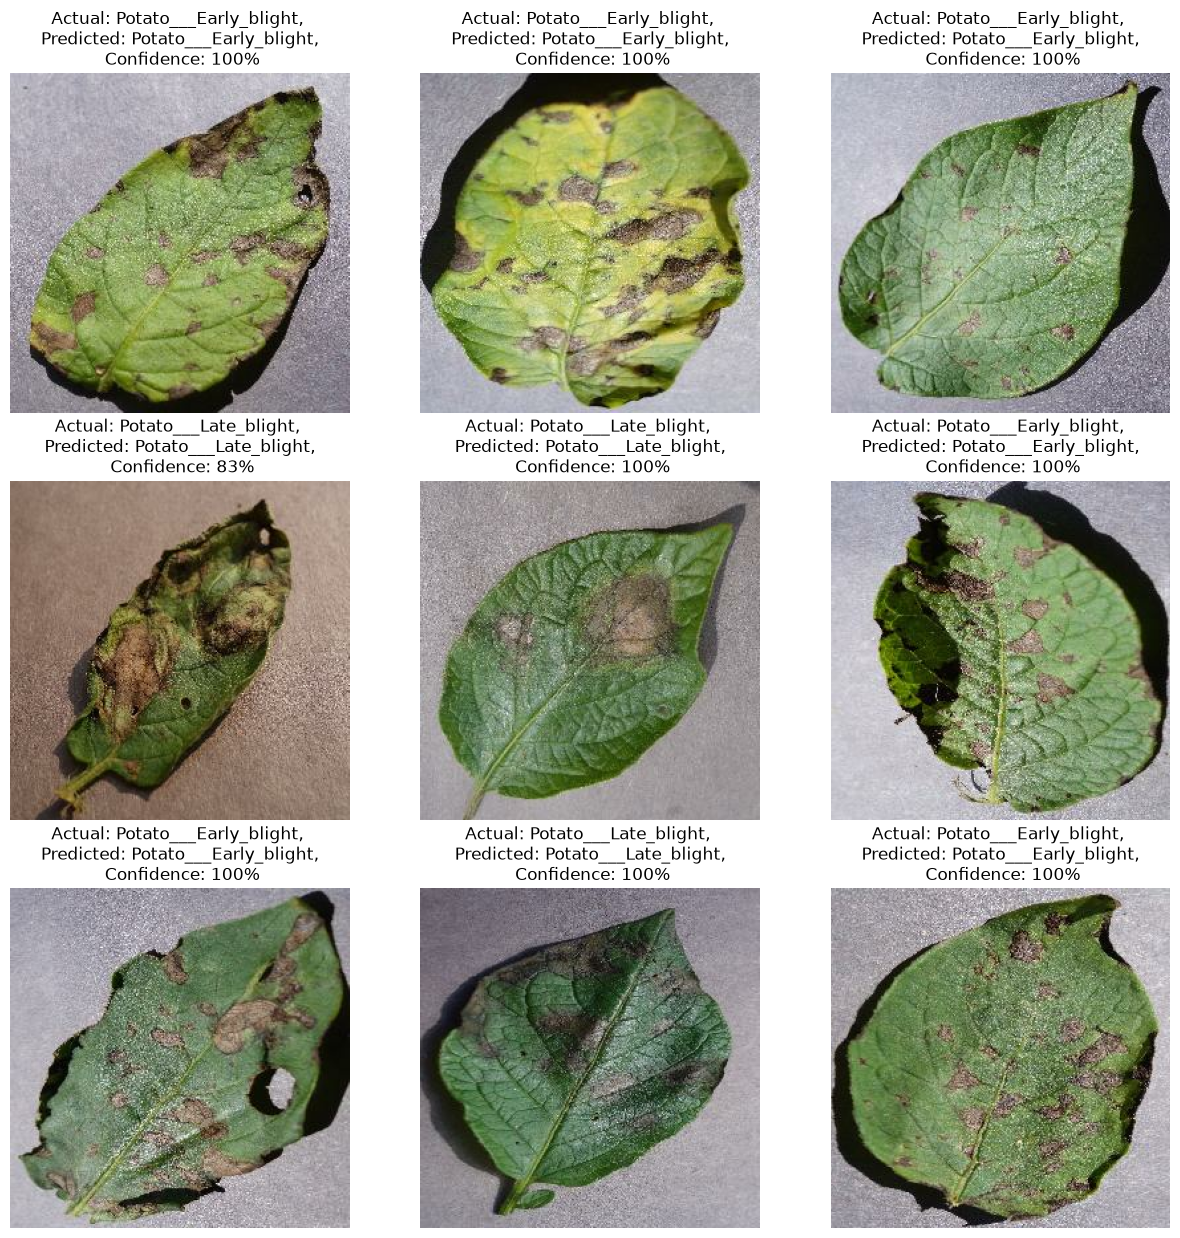

In [27]:
# Show 9 test images with actual label, predicted label and confidence
plt.figure(figsize = (15, 15))
for images, labels in test_data.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i+1)
        plt.imshow(images[i].numpy().astype("uint8"))

        predicted_class, confidence = predict(model, images[i].numpy())
        actual_class = class_names[labels[i]]

        plt.title(f"Actual: {actual_class}, \n Predicted: {predicted_class}, \n Confidence: {round(confidence)}%")
        plt.axis("off")

In [28]:
# Save the trained model in a new numbered folder (models/1, models/2, ...)
# so earlier versions are never overwritten. The [0] handles the empty-folder case.
import os
model_version = max([int(i) for i in os.listdir("models") + [0]]) + 1
model.export(f"models/{model_version}")   # export as a TensorFlow SavedModel for serving/deployment

INFO:tensorflow:Assets written to: models/3\assets


INFO:tensorflow:Assets written to: models/3\assets


Saved artifact at 'models/3'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  2020745856400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2020745855824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2020745866960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2020745867728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2020745866000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2020745866384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2020745868880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2020745868112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2020745869264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2020745869072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2020745866576: TensorSpec(shape=(), dtype=